## Phase 1: Business Understanding

**My question**
Do richer countries really have fewer children dying and people living longer, and has child mortality actually dropped since 2000?

**Why it matters**
If money and health move together that closely, then the poorest countries are where help should go first, and growth helps over time. If they don't, then income isn't the whole story, and funders should back things like immunisation and basic healthcare instead of waiting for economies to grow.

**My hunch**
I think richer countries will have far lower child mortality, and that life expectancy will be 20 years longer in the richest income group than in the poorest. I also think child mortality has dropped in most countries since 2000.

**What could prove me wrong**
No difference in child mortality between income groups, no difference in life expectancy between the richest and poorest groups, or no real change in child mortality between 2000 and 2024.


In [9]:
import pandas as pd
import numpy as np

## Phase 2 — Data Understanding

### Loading data from all four sources

In [10]:
files = {
    "life_expectancy": "life_expectancy_raw.csv",
    "child_mortality": "child_mortality_raw.csv",
    "gdp_per_capita": "gdp_per_capita_raw.csv",
    "population": "population_raw.csv",
}

sources = {}
for name, path in files.items():
    d = pd.read_csv(path, na_values="..")                   # '..' becomes NaN so it can be counted
    d = d.rename(columns={d.columns[0]: "Country Name"})    # guards against a stray character in the header
    d = d[d["Series Code"].notna()]                         # drops any blank or footer rows
    d.columns = [c.split(" [")[0] for c in d.columns]       # '1960 [YR1960]' -> '1960'
    sources[name] = d.drop(columns=["Series Name", "Series Code"]).reset_index(drop=True)

year_cols = [c for c in sources["life_expectancy"].columns if c.isdigit()]

for name, d in sources.items():
    print(name, d.shape)
    print(d[["1960", "2000", "2024"]].describe().round(2))
    print("missing:", d[year_cols].isna().sum().sum(), "of", d[year_cols].size,
          f"({d[year_cols].isna().mean().mean():.1%})")

life_expectancy (262, 68)
        1960   2000   2024
count 259.00 261.00 261.00
mean   54.16  67.31  73.80
std    11.63   9.37   6.88
min    28.05  44.83  54.64
25%    43.59  61.81  68.89
50%    54.62  70.17  74.58
75%    64.40  74.58  78.92
max    74.04  82.12  86.50
missing: 361 of 17292 (2.1%)
child_mortality (262, 68)
        1960   2000   2024
count 131.00 240.00 240.00
mean  151.66  57.58  25.40
std   102.31  54.44  24.63
min    19.60   3.90   1.30
25%    54.65  14.10   6.78
50%   137.20  35.90  15.70
75%   219.65  89.98  37.75
max   434.40 227.90 115.60
missing: 3891 of 17292 (22.5%)
gdp_per_capita (262, 68)
          1960      2000       2024
count   148.00    248.00     244.00
mean    476.33  7,650.59  20,895.07
std     598.28 12,295.72  33,014.24
min      25.08    122.27     216.23
25%     119.00    632.45   2,697.58
50%     221.57  1,826.35   7,852.45
75%     513.94  9,428.20  25,325.84
max   2,999.86 81,789.01 288,001.57
missing: 2745 of 17292 (15.9%)
population (262, 68)
 

## Mean, Median, Std deviation...

In [11]:
# Pool every country-year value in each source into one series (missing values dropped)
values = {name: pd.Series(d[year_cols].to_numpy().ravel()).dropna()
          for name, d in sources.items()}

# Central tendency and spread, one row per dataset
summary = pd.DataFrame({
    name: v.agg(["count", "mean", "median", "std", "min", "max", "skew"])
    for name, v in values.items()
}).T
summary["IQR"] = [v.quantile(0.75) - v.quantile(0.25) for v in values.values()]
summary["CV"] = summary["std"] / summary["mean"]
pd.options.display.float_format = "{:,.2f}".format
print(summary)



                    count           mean       median            std      min  \
life_expectancy 16,931.00          65.01        67.47          11.06    10.99   
child_mortality 13,401.00          70.05        40.80          75.06     1.30   
gdp_per_capita  14,547.00       9,008.77     2,033.95      18,047.39    11.80   
population      17,196.00 198,560,579.36 6,502,353.00 641,715,986.08 2,715.00   

                             max  skew           IQR   CV  
life_expectancy            86.50 -0.70         14.93 0.17  
child_mortality           780.90  1.73         81.51 1.07  
gdp_per_capita        288,001.57  4.57      7,779.38 2.00  
population      6,993,790,788.00  5.49 40,367,452.00 3.23  


## Plotting my data

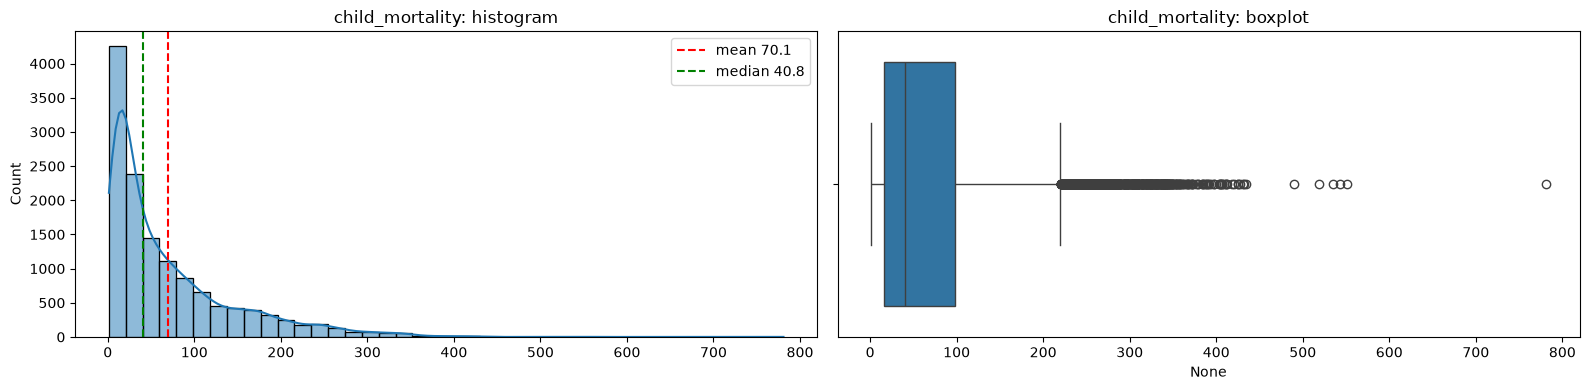

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns

name = "child_mortality"  # or 'child_mortality_rate' / 'under_five_mortality'
v = values[name]

# Wide side-by-side layout (16x4)
fig, axes = plt.subplots(1, 2, figsize=(16, 4))

# Histogram with KDE, mean, and median
sns.histplot(v, bins=40, kde=True, ax=axes[0])
axes[0].axvline(v.mean(), color="red", linestyle="--", label=f"mean {v.mean():,.1f}")
axes[0].axvline(v.median(), color="green", linestyle="--", label=f"median {v.median():,.1f}")
axes[0].set_title(f"{name}: histogram")
axes[0].legend()

# Boxplot
sns.boxplot(x=v, ax=axes[1])
axes[1].set_title(f"{name}: boxplot")

plt.tight_layout()
plt.show()

Right-Skewed (Positively Skewed): The histogram features a heavy concentration of observations on the lower end (representing regions with low child mortality) and a long tail stretching toward higher mortality rates on the right.

Mean vs. Median: The mean will typically sit higher than the median, as it is pulled upward by the long right-hand tail and high-mortality outliers.

Boxplot Appearance: The interquartile range (the box) is compressed toward the lower values, with the median line positioned toward the left of the box, followed by an elongated right whisker and a series of high-value outliers.

## Phase 3 — Data Preparation

## Joining

In [14]:
def to_long(d, name):
    out = d.melt(id_vars=["Country Name", "Country Code"], value_vars=year_cols,
                 var_name="year", value_name=name)
    out["year"] = out["year"].astype(int)
    out[name] = pd.to_numeric(out[name], errors="coerce").astype("float64")
    return out

long_tables = {name: to_long(d, name) for name, d in sources.items()}
for name, t in long_tables.items():
    print(f"{name}: {t.shape[0]} rows, {t[name].isna().sum()} missing")

life_expectancy: 17292 rows, 361 missing
child_mortality: 17292 rows, 3891 missing
gdp_per_capita: 17292 rows, 2745 missing
population: 17292 rows, 96 missing


In [15]:
print("Rows before join:", {n: len(t) for n, t in long_tables.items()})

names = list(long_tables)
merged = long_tables[names[0]]
for n in names[1:]:
    merged = merged.merge(long_tables[n].drop(columns="Country Name"),
                          on=["Country Code", "year"], how="inner")

print("Rows after join:", len(merged))
print("Unique keys (country, year):", merged[["Country Code", "year"]].drop_duplicates().shape[0])

Rows before join: {'life_expectancy': 17292, 'child_mortality': 17292, 'gdp_per_capita': 17292, 'population': 17292}
Rows after join: 17292
Unique keys (country, year): 17292


## Handling Missing Values

In [16]:
cols = ["life_expectancy", "child_mortality", "gdp_per_capita", "population"]
print(merged[cols].isna().sum())
print(merged.groupby("year")[cols].apply(lambda g: g.isna().mean().mean()).round(2).iloc[::10])

before = len(merged)
merged = merged.dropna(subset=cols).reset_index(drop=True)
print(f"Dropped {before - len(merged)} rows; {len(merged)} remain")
print("missing values:", merged[cols].isna().sum().sum())

life_expectancy     361
child_mortality    3891
gdp_per_capita     2745
population           96
dtype: int64
year
1960   0.24
1970   0.18
1980   0.14
1990   0.05
2000   0.04
2010   0.03
2020   0.03
dtype: float64
Dropped 5227 rows; 12065 remain
missing values: 0


My question needs all four indicators for the same country and year, so I dropped any row with a missing value. Filling with the mean would flatten the relationships I am testing, and filling in missing years would mean making up values. The missing data is mostly in the early years, so poorer and less well-documented countries are underrepresented. 

## Removing aggregates

In [17]:
aggregates = ["AFE", "AFW", "ARB", "CEB", "CSS", "EAR", "EAS", "ECA", "ECS", "EMU",
              "EUU", "FCS", "HIC", "HPC", "IBD", "IBT", "IDA", "IDB", "IDX", "INX",
              "LAC", "LCN", "LDC", "LIC", "LMC", "LMY", "LTE", "MEA", "MIC", "MNA",
              "NAC", "OED", "OSS", "PRE", "PSS", "PST", "SAS", "SSA", "SSF", "SST",
              "TEA", "TEC", "TLA", "TMN", "TSA", "TSS", "UMC", "WLD"]

before = len(merged)
df_clean = merged[~merged["Country Code"].isin(aggregates)]
df_clean = df_clean[~df_clean["Country Name"].str.contains("excluding high income")]
print(f"Removed {before - len(df_clean)} aggregate rows; {len(df_clean)} remain, {df_clean['Country Code'].nunique()} countries")


Removed 1540 aggregate rows; 10525 remain, 194 countries


In [35]:
df_clean = df_clean.copy()
df_clean["gdp_per_capita"] = df_clean["gdp_per_capita"].round(2)
df_clean["decade"] = (df_clean["year"] // 10) * 10
df_clean["gdp_quartile"] = pd.qcut(df_clean["gdp_per_capita"], q=4,
                                   labels=["Q1 (lowest)", "Q2", "Q3", "Q4 (highest)"])
print(df_clean["gdp_quartile"].value_counts())

gdp_quartile
Q1 (lowest)     2632
Q2              2631
Q3              2631
Q4 (highest)    2631
Name: count, dtype: int64



*gdp_quartile* is the grouping variable for my t-tests. I chose not to use the country metadata table, which holds the official World Bank income classes.
 
*decade* supports period comparisons

In [40]:
df_clean = df_clean.drop(columns=["log_gdp", "log_mortality"], errors="ignore")
df_clean.to_csv("clean_data.csv", index=False)

In [41]:
df_clean = df_clean.reset_index(drop=True)
assert df_clean[cols].isna().sum().sum() == 0
assert df_clean.duplicated(["Country Code", "year"]).sum() == 0
print(df_clean.shape)
df_clean.info()
df_clean.to_csv("clean_data.csv", index=False)

(10525, 9)
<class 'pandas.DataFrame'>
RangeIndex: 10525 entries, 0 to 10524
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype   
---  ------           --------------  -----   
 0   Country Name     10525 non-null  str     
 1   Country Code     10525 non-null  str     
 2   year             10525 non-null  int64   
 3   life_expectancy  10525 non-null  float64 
 4   child_mortality  10525 non-null  float64 
 5   gdp_per_capita   10525 non-null  float64 
 6   population       10525 non-null  float64 
 7   decade           10525 non-null  int64   
 8   gdp_quartile     10525 non-null  category
dtypes: category(1), float64(4), int64(2), str(2)
memory usage: 793.5 KB


## Phase 5 — Evaluation

## Friedman Test

It compares typical GDP across decades using each country’s ranks

*H₀*: the distribution of GDP per capita is the same in every decade.

*H₁*: GDP per capita differs in at least one decade.

*α* = 0.05

In [48]:

import pandas as pd
import scikit_posthocs as sp
from scipy import stats

# One value per country per decade (median of that decade's years)
cd = (df_clean.groupby(["Country Code", "decade"], as_index=False)["gdp_per_capita"]
      .median())

# Keep only countries with data in every decade
wide = cd.pivot(index="Country Code", columns="decade", values="gdp_per_capita").dropna()
n, k = wide.shape
print(f"{n} countries with data in all {k} decades")

# Describe the decades (medians, because of the skew)
print(wide.median().round(0))

# Friedman test and effect size (Kendall's W)
chi2, p = stats.friedmanchisquare(*[wide[c] for c in wide.columns])
kendall_w = chi2 / (n * (k - 1))

alpha = 0.05
print(f"Friedman chi-square({k - 1}) = {chi2:.1f}, p = {p:.3g}, n = {n}")
print(f"Kendall's W = {kendall_w:.2f}")
print("Decision:", "REJECT H0" if p < alpha else "FAIL TO REJECT H0", f"at alpha = {alpha}")



113 countries with data in all 7 decades
decade
1960     281.00
1970     670.00
1980   1,265.00
1990   1,876.00
2000   2,755.00
2010   5,659.00
2020   6,189.00
dtype: float64
Friedman chi-square(6) = 613.3, p = 3.1e-129, n = 113
Kendall's W = 0.90
Decision: REJECT H0 at alpha = 0.05


Medians: typical GDP per capita rises from $281 in the 1960s to $6,189 in the 2020s, about 22 times higher. Most of the climb is steady, with a larger jump between the 2000s ($2,755) and the 2010s ($5,659).

χ²(6) = 613.3: the decades differ far more than chance would produce. The 6 degrees of freedom come from 7 decades minus 1.

p = 3.1e-129: report this as p < 0.001. If GDP did not change across decades, a result this extreme would be essentially impossible, so you reject H₀.

Kendall’s W = 0.90: this is the effect size, from 0 to 1. It means countries agree strongly on the order of the decades. Almost every country had its lowest GDP early and its highest late.



P-value is not the probability that H₀ is true, and it does not measure the size of an effect or explain its cause. The size here comes from W = 0.90 and the medians.

## CHI squared

### Test: chi-square test of independence
Is income group related to whether a country's life expectancy is 70 years or more? I used 2024 only, so each country appears once.

**α = 0.05**

**H0:** GDP per capita quartile and life expectancy category (70 or more vs under 70) are independent.

**H1:** they are associated: the share with life expectancy of 70 or more differs across quartiles.

In [21]:

latest = df_clean[df_clean["year"] == 2024].copy()
latest["quartile"] = pd.qcut(latest["gdp_per_capita"], 4,
                             labels=["Q1 (lowest)", "Q2", "Q3", "Q4 (highest)"])
latest["long_life"] = np.where(latest["life_expectancy"] >= 70, "70 or more", "under 70")

ct = pd.crosstab(latest["quartile"], latest["long_life"])
chi2, p, dof, expected = stats.chi2_contingency(ct)
cramers_v = np.sqrt(chi2 / (len(latest) * (min(ct.shape) - 1)))

print(ct)
print(ct.div(ct.sum(axis=1), axis=0).round(2))        # row percentages
print(f"n = {len(latest)}")
print(f"chi-square({dof}) = {chi2:.1f}, p = {p:.3g}, Cramer's V = {cramers_v:.2f}")
print("Smallest expected count:", expected.min().round(1), "(should be 5 or more)")
print("Decision:", "REJECT H0" if p < 0.05 else "FAIL TO REJECT H0", "at alpha = 0.05")

long_life     70 or more  under 70
quartile                          
Q1 (lowest)            6        41
Q2                    32        15
Q3                    42         5
Q4 (highest)          47         0
long_life     70 or more  under 70
quartile                          
Q1 (lowest)         0.13      0.87
Q2                  0.68      0.32
Q3                  0.89      0.11
Q4 (highest)        1.00      0.00
n = 188
chi-square(3) = 97.1, p = 6.39e-21, Cramer's V = 0.72
Smallest expected count: 15.2 (should be 5 or more)
Decision: REJECT H0 at alpha = 0.05


 The share of countries with life expectancy of 70 or more rises from 13% in the lowest GDP quartile (6 of 47) to 68%, 89% and 100% (47 of 47) in the highest. The smallest expected count is 15.2, so the test's assumption (5 or more) holds.

Reject H0 at α = 0.05, because p < 0.05.

Income group and life expectancy category are strongly associated: in 2024, only 13% of countries in the lowest GDP quartile reach a life expectancy of 70, against every country in the highest quartile.

P-value is not the probability that H0 is true or that the association is due to chance, and it does not say how strong the association is. It does not show that income causes longer life, and it does not say which quartiles differ. 

## Paired t-test

 A paired t-test compares the same units measured twice, such as before and after, and asks whether the average change differs from zero.

**H0:** the mean change in life expectancy between 2000 and 2024 is zero.

**H1:** the mean change in life expectancy is not zero.

paired t-test (life expectancy, 2000 vs 2024)

In [44]:

from scipy import stats

pair = (df_clean[df_clean["year"].isin([2000, 2024])]
        .pivot(index="Country Code", columns="year", values="life_expectancy")
        .dropna())
n = len(pair)

t, p = stats.ttest_rel(pair[2024], pair[2000])
diff = pair[2024] - pair[2000]                    # positive = life expectancy rose
d = diff.mean() / diff.std(ddof=1)                # Cohen's d for paired data
ci = stats.t.interval(0.95, n - 1, loc=diff.mean(), scale=stats.sem(diff))

alpha = 0.05
print(f"{n} countries with data in both years")
print(f"t({n - 1}) = {t:.1f}, p = {p:.3g}")
print(f"Cohen's d = {d:.2f}")
print(f"Mean gain = {diff.mean():.1f} years (95% CI {ci[0]:.1f} to {ci[1]:.1f})")
print(f"{(diff > 0).mean():.0%} of countries gained life expectancy")
print("Decision:", "REJECT H0" if p < alpha else "FAIL TO REJECT H0", f"at alpha = {alpha}")

186 countries with data in both years
t(185) = 21.8, p = 4.88e-53
Cohen's d = 1.60
Mean gain = 6.7 years (95% CI 6.1 to 7.3)
99% of countries gained life expectancy
Decision: REJECT H0 at alpha = 0.05


The p-value (4.88e-53) is not the probability that H0 is true, and it is not the probability that the fall in mortality happened by chance

Across the 186 countries with data in both years, about 184 improved. 98% of countries gained with an avaerage country gaining 6.7 years of life expectancy over 24 years.

## A/B Style Test

**Groups were not randomly assigned.** Countries were already in the richer or poorer half, so a significant result shows the groups differ, but it does not by itself prove that income caused the difference, as a randomized A/B test could.

Do countries in the richer half meet the UN child mortality target more often than countries in the poorer half? 

**Groups (2024 only, so each country appears once):**
A = countries below the median GDP per capita, B = countries at or above it.

**Metric:** share of countries with under-5 mortality of 25 or fewer per 1,000 live births (the UN SDG target).

**α = 0.05**

**H0:** the share meeting the target is the same in both groups (pA = pB).

**H1:** the share is different between the groups (pA ≠ pB).

In [23]:
latest = df_clean[df_clean["year"] == 2024].copy()
latest["group"] = np.where(latest["gdp_per_capita"] >= latest["gdp_per_capita"].median(),
                           "B: above median", "A: below median")
latest["hit_target"] = latest["child_mortality"] <= 25

s = latest.groupby("group")["hit_target"].agg(successes="sum", n="count")
xA, nA = s.loc["A: below median"]
xB, nB = s.loc["B: above median"]
pA, pB = xA / nA, xB / nB

pool = (xA + xB) / (nA + nB)
z = (pB - pA) / np.sqrt(pool * (1 - pool) * (1 / nA + 1 / nB))
p = 2 * stats.norm.sf(abs(z))
se = np.sqrt(pA * (1 - pA) / nA + pB * (1 - pB) / nB)

print(s)
print(f"A: {pA:.0%} meet the target | B: {pB:.0%}")
print(f"Difference = {pB - pA:.0%} points (95% CI {pB - pA - 1.96 * se:.0%} to {pB - pA + 1.96 * se:.0%})")
print(f"z = {z:.2f}, p = {p:.3g}")
print("Smallest cell (successes or failures):", min(xA, nA - xA, xB, nB - xB))

odds, p_fisher = stats.fisher_exact([[xA, nA - xA], [xB, nB - xB]])
print(f"Fisher exact check: p = {p_fisher:.3g}")
print("Decision:", "REJECT H0" if p < 0.05 else "FAIL TO REJECT H0", "at alpha = 0.05")

                 successes   n
group                         
A: below median         37  94
B: above median         88  94
A: 39% meet the target | B: 94%
Difference = 54% points (95% CI 43% to 65%)
z = 7.88, p = 3.27e-15
Smallest cell (successes or failures): 6
Fisher exact check: p = 4.59e-16
Decision: REJECT H0 at alpha = 0.05


Reject H0 at α = 0.05, because p < 0.05. The share of countries meeting the child mortality target differs sharply between the richer and poorer halves.

 Among the 188 countries with 2024 data, those in the richer half were far more likely to meet the target of 25 or fewer under-5 deaths per 1,000 live births (94% vs 39%).


The p-value is not the probability that H0 is true or that the gap is due to chance. It does not say how big the gap is: that comes from the 54-point difference and its confidence interval. 